# EDA - Phân tích dữ liệu sản phẩm Lazada

Dataset: `data/preprocessed/sanpham_cleaned.csv`

**Mục tiêu:** Khám phá và phân tích dataset danh sách sản phẩm mỹ phẩm trên Lazada Việt Nam sau khi đã qua bước tiền xử lý.

## 1. Import thư viện & Đọc dữ liệu

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
sns.set_theme(style='whitegrid', palette='muted')

DATA_PATH = '../../data/preprocessed/sanpham_cleaned.csv'
df = pd.read_csv(DATA_PATH)

print(f'Đã đọc dữ liệu: {df.shape[0]:,} hàng × {df.shape[1]} cột')
print(f'Đơn vị GIÁ: nghìn đồng (VNĐ)')
df.head(3)

Đã đọc dữ liệu: 7,027 hàng × 13 cột
Đơn vị GIÁ: nghìn đồng (VNĐ)


,ID Sản phẩm,Tên sản phẩm,Danh mục,Giá,Giảm giá,Đã bán,Điểm đánh giá,Lượt đánh giá,Địa điểm,Đường dẫn,Hình ảnh,Tên shop,Seller ID
0,3140194631,100% hàng thậtLa Roche-Posay Cicaplast Baume B...,Chăm Sóc Da,189.140,0.42,156,4.9,28.0,Vietnam,https://www.lazada.vn/products/pdp-i3140194631...,https://img.lazcdn.com/g/p/67ba4e5cd4ccb841708...,AuraBelle,2.009840e+11
1,2496648405,Bộ Chăm Sóc Da Hoa Mận LAIKOU Nhật Bản - 5 Sản...,Chăm Sóc Da,56.000,0.23,2800,4.9,1042.0,Vietnam,https://www.lazada.vn/products/pdp-i2496648405...,https://img.lazcdn.com/g/p/36828d8a5434f8c5a65...,LAIKOU.Selection,2.005483e+11
2,2784492770,Pores serum Thu Nhỏ Lỗ Chân Lông Úc Tinh Chất ...,Chăm Sóc Da,55.656,0.45,339,5.0,100.0,Vietnam,https://www.lazada.vn/products/pdp-i2784492770...,https://img.lazcdn.com/g/p/b75cb8329d690d4a901...,On Moon,2.001644e+11


## 2. Tổng quan cấu trúc dữ liệu

In [7]:
print('=== THÔNG TIN DATASET ===')
df.info()
print('\n=== THỐNG KÊ MÔ TẢ ===')
df.describe(include='all')

=== THÔNG TIN DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7027 entries, 0 to 7026
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID Sản phẩm    7027 non-null   int64  
 1   Tên sản phẩm   7027 non-null   object 
 2   Danh mục       7027 non-null   object 
 3   Giá            7027 non-null   float64
 4   Giảm giá       7027 non-null   float64
 5   Đã bán         7027 non-null   int64  
 6   Điểm đánh giá  5561 non-null   float64
 7   Lượt đánh giá  7027 non-null   float64
 8   Địa điểm       7027 non-null   object 
 9   Đường dẫn      7027 non-null   object 
 10  Hình ảnh       7027 non-null   object 
 11  Tên shop       6725 non-null   object 
 12  Seller ID      6943 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 713.8+ KB

=== THỐNG KÊ MÔ TẢ ===


,ID Sản phẩm,Tên sản phẩm,Danh mục,Giá,Giảm giá,Đã bán,Điểm đánh giá,Lượt đánh giá,Địa điểm,Đường dẫn,Hình ảnh,Tên shop,Seller ID
count,7.027000e+03,7027,7027,7027.000000,7027.000000,7027.000000,5561.000000,7027.000000,7027,7027,7027,6725,6.943000e+03
unique,NaN,6916,9,NaN,NaN,NaN,NaN,NaN,53,7014,3527,1888,NaN
top,NaN,Bộ cờ Lê (cle )8-24 YEII 14 CHI TIẾT ( USA STA...,Trang phục nam,NaN,NaN,NaN,NaN,NaN,Hồ Chí Minh,https://www.lazada.vn/products/pdp-i2997580823...,"data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAA...",TB FASHION STORE,NaN
freq,NaN,5,2044,NaN,NaN,NaN,NaN,NaN,2350,2,3478,354,NaN
mean,2.971357e+09,NaN,NaN,960.698364,0.267202,436.656326,4.820842,76.702718,NaN,NaN,NaN,NaN,1.558040e+11
std,2.256869e+09,NaN,NaN,4426.269616,0.223169,3752.125963,0.387942,459.626366,NaN,NaN,NaN,NaN,8.325404e+10
min,1.216257e+06,NaN,NaN,2.500000,0.000000,5.000000,1.000000,0.000000,NaN,NaN,NaN,NaN,7.870000e+02
25%,2.200981e+09,NaN,NaN,95.000000,0.020000,12.000000,4.800000,1.000000,NaN,NaN,NaN,NaN,2.001605e+11
50%,2.711734e+09,NaN,NaN,202.000000,0.250000,36.000000,5.000000,6.000000,NaN,NaN,NaN,NaN,2.001949e+11
75%,3.196765e+09,NaN,NaN,409.800000,0.440000,152.000000,5.000000,29.000000,NaN,NaN,NaN,NaN,2.005270e+11


## 3. Kiểm tra Missing Values

=== MISSING VALUES ===
               Missing Count  Missing %
Điểm đánh giá           1466      20.86
Tên shop                 302       4.30
Seller ID                 84       1.20


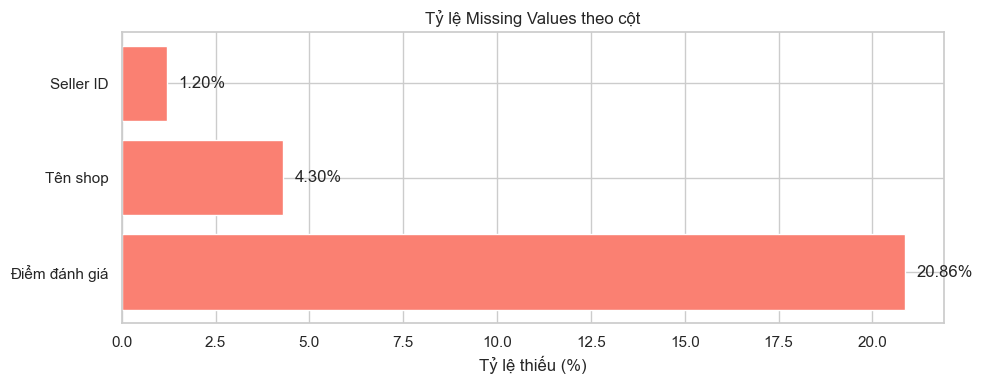

In [8]:
missing = df.isnull().sum()
pct = (missing / len(df) * 100).round(2)
miss_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': pct
}).sort_values('Missing Count', ascending=False)

print('=== MISSING VALUES ===')
print(miss_df[miss_df['Missing Count'] > 0])

# Visualize
miss_plot = miss_df[miss_df['Missing Count'] > 0]
if not miss_plot.empty:
    fig, ax = plt.subplots(figsize=(10, 4))
    bars = ax.barh(miss_plot.index, miss_plot['Missing %'], color='salmon', edgecolor='white')
    ax.set_xlabel('Tỷ lệ thiếu (%)')
    ax.set_title('Tỷ lệ Missing Values theo cột')
    for bar, val in zip(bars, miss_plot['Missing %']):
        ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                f'{val:.2f}%', va='center')
    plt.tight_layout()
    plt.show()
else:
    print('✅ Không có missing values!')

In [9]:
# Kiểm tra các dòng bị thiếu đồng thời cả Tên shop và Seller ID
missing_both = df[df['Tên shop'].isnull() & df['Seller ID'].isnull()]

print(f"Số lượng dòng thiếu cả Tên shop và Seller ID: {len(missing_both)}")

# Lưu lại số lượng dòng trước khi xóa
old_len = len(df)

# Bỏ các dòng thiếu đồng thời cả 'Tên shop' và 'Seller ID'
# how='all' nghĩa là chỉ xóa nếu TẤT CẢ các cột trong subset đều là NaN
df = df.dropna(subset=['Tên shop', 'Seller ID'], how='all')

# Tính số dòng đã xóa
removed_count = old_len - len(df)
print(f"Đã xóa {removed_count} dòng bị trống cả Tên shop và Seller ID.")
print(f"Số lượng dòng còn lại: {len(df):,}")

Số lượng dòng thiếu cả Tên shop và Seller ID: 6
Đã xóa 6 dòng bị trống cả Tên shop và Seller ID.
Số lượng dòng còn lại: 7,021


In [10]:
# 1. Đọc dữ liệu shop đã làm sạch (Chứa cột 'Tên shop' và 'Seller ID' dạng S000x)
df_shop_ref = pd.read_csv('../../data/preprocess and eda/shop_cleaned.csv')

# 2. Tạo mapping {Tên shop: Seller ID chuẩn S000x}
shop_mapping = dict(zip(df_shop_ref['Tên shop'], df_shop_ref['Seller ID']))

# 3. Ưu tiên lấy Seller ID mới theo Tên shop
# Thay vì dùng hàm map_seller_id cũ, ta dùng map trực tiếp
df['Seller ID'] = df['Tên shop'].map(shop_mapping)

# 4. Những shop không khớp được thì mới để S0000 hoặc Unknown
df['Seller ID'] = df['Seller ID'].fillna("S0000")
df['Tên shop'] = df['Tên shop'].fillna("Unknown")

# 5. Cấp lại ID sản phẩm
df['ID Sản phẩm'] = [f"P{str(i).zfill(4)}" for i in range(1, len(df) + 1)]

# Bỏ cột Đường dẫn và Hình ảnh
df = df.drop(columns=['Đường dẫn', 'Hình ảnh'], errors='ignore')

# 6. Lưu lại
df.to_csv('../../data/preprocess and eda/sanpham_cleaned.csv', index=False, encoding='utf-8-sig')

# --- IN KẾT QUẢ KIỂM TRA ---
print(f"Số lượng dòng: {len(df)}")
print("\n5 dòng đầu tiên sau khi chuẩn hóa:")
display(df[['ID Sản phẩm', 'Tên sản phẩm', 'Tên shop', 'Seller ID']].head())

print("\nKiểm tra một vài dòng có Seller ID được map thành công:")
display(df[df['Seller ID'] != "S0000"][['ID Sản phẩm', 'Tên shop', 'Seller ID']].head())

Số lượng dòng: 7021

5 dòng đầu tiên sau khi chuẩn hóa:


,ID Sản phẩm,Tên sản phẩm,Tên shop,Seller ID
0,P0001,100% hàng thậtLa Roche-Posay Cicaplast Baume B...,AuraBelle,S0001
1,P0002,Bộ Chăm Sóc Da Hoa Mận LAIKOU Nhật Bản - 5 Sản...,LAIKOU.Selection,S0002
2,P0003,Pores serum Thu Nhỏ Lỗ Chân Lông Úc Tinh Chất ...,On Moon,S0003
3,P0004,Bộ chăm sóc da VIBRANT GLAMOUR ANNIES với tone...,ddddVN.Selection,S0004
4,P0005,Serum meiduzi x2 tem vuông phục hồi cấp ẩm - S...,Shopđẹp24h chuyên hàng chính hãng,S0005



Kiểm tra một vài dòng có Seller ID được map thành công:


,ID Sản phẩm,Tên shop,Seller ID
0,P0001,AuraBelle,S0001
1,P0002,LAIKOU.Selection,S0002
2,P0003,On Moon,S0003
3,P0004,ddddVN.Selection,S0004
4,P0005,Shopđẹp24h chuyên hàng chính hãng,S0005


### Nhận xét về dữ liệu thiếu

Có tổng cộng 3 cột chứa giá trị thiếu, chủ yếu do đặc thù phân phối sản phẩm mới:

1.  **Điểm đánh giá (20.86%)**: Do sản phẩm chưa có lượt mua/đánh giá thực tế. Đây là dữ liệu khuyết tự nhiên.
2.  **Tên shop (4.30%)**: Do lỗi trích xuất thông tin hoặc shop tạm ẩn tại thời điểm thu thập.
3.  **Seller ID (1.20%)**: Sai số ngẫu nhiên trong quá trình thu thập dữ liệu.

### Đề xuất hướng xử lý Tiền xử lý

Để đảm bảo tính khách quan của tập dữ liệu:

*   **Điểm đánh giá**: Tạm thời **giữ nguyên `NaN`** để tránh làm sai lệch điểm số trung bình thực của các sản phẩm có tương tác.
*   **Tên shop**: Điền giá trị chuỗi **`"Unknown"`**.
*   **Seller ID**: Với những dòng bị thiếu Seller ID nhưng có Tên shop trong data Product, ta sẽ tra cứu vào Dictionary để điền ID tương ứng.

# Mô Tả Tập Dữ Liệu Sản Phẩm Lazada - Sau Xử Lý Tiền Xử Lý

## Cấu Trúc Dữ Liệu

Tập dữ liệu bao gồm **11 cột (Features)** được chia thành **3 nhóm chính**:

### Nhóm 1: Xác Định Sản Phẩm (Categorical)

| Cột | Mô Tả |
|-----|-------|
| **ID Sản phẩm** | Mã định danh duy nhất cho mỗi sản phẩm (ví dụ: P0001, P0002, ...) |
| **Tên sản phẩm** | Tên gọi đầy đủ của sản phẩm trên sàn Lazada |
| **Danh mục** | Phân loại sản phẩm theo ngành hàng (ví dụ: Chăm Sóc Da, Trang Điểm, Nước Hoa,...) |
| **Địa điểm** | Vị trí địa lý của người bán (Vietnam, Hồ Chí Minh, Đà Nẵng,...) |

### Nhóm 2: Chỉ Số Kinh Doanh (Numerical)

| Cột | Mô Tả |
|-----|-------|
| **Giá** | Giá bán sản phẩm (tính bằng nghìn đồng - VNĐ) |
| **Giảm giá** | Tỷ lệ phần trăm khuyến mãi được áp dụng (từ 0 đến 1, ví dụ: 0.42 = 42%) |
| **Đã bán** | Số lượng sản phẩm đã bán (tính bằng đơn hàng) |
| **Điểm đánh giá** | Mức đánh giá trung bình từ khách hàng (từ 0-5 sao) |
| **Lượt đánh giá** | Số lượng khách hàng đã để lại đánh giá |

### Nhóm 3: Thông Tin Bán Hàng (Categorical)

| Cột | Mô Tả |
|-----|-------|
| **Tên shop** | Tên cửa hàng/đơn vị bán hàng trên Sàn Lazada |
| **Seller ID** | Mã định danh của người bán (ví dụ: S0001, S0002,...) |

## 4.1. Phân tích mối quan hệ giữa Điểm đánh giá và Lượt đánh giá

> **Lưu ý thiết kế:** Điểm đánh giá được để **rỗng (NaN)** khi **Lượt đánh giá = 0**.
> Điều này hoàn toàn hợp lý về mặt ngữ nghĩa: nếu chưa có ai đánh giá, điểm trung bình không tồn tại.

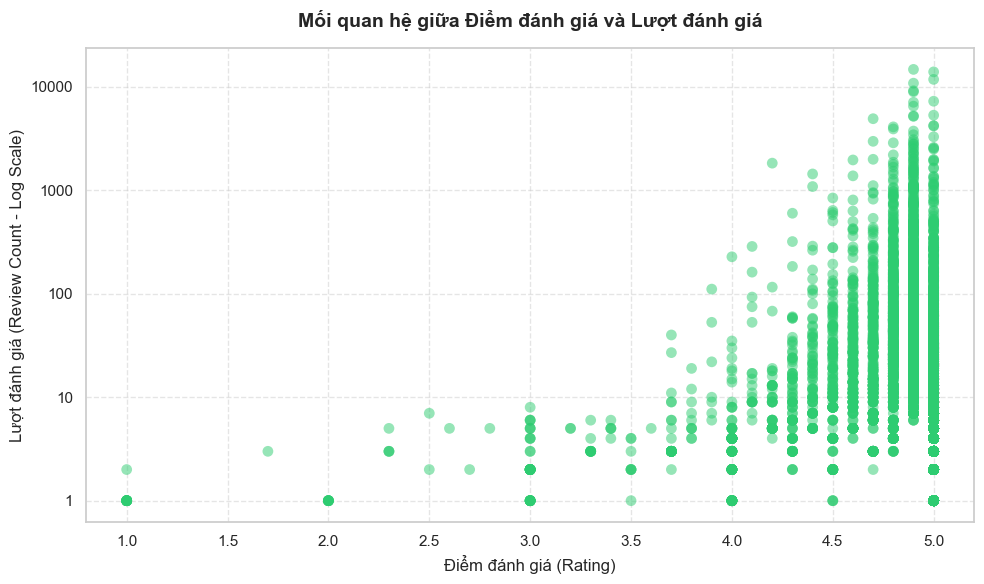

In [11]:
# Tạo DataFrame gồm những sản phẩm đã có điểm đánh giá
df_rated = df[df['Điểm đánh giá'].notnull()].copy()

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df_rated, x='Điểm đánh giá', y='Lượt đánh giá', 
                alpha=0.5, color='#2ecc71', s=60, edgecolor='none', ax=ax)

# Sử dụng thang đo log cho trục Y do sự phân tán (kéo dài) lớn của lượt đánh giá
import matplotlib.ticker as mticker
ax.set_yscale('log')
ax.get_yaxis().set_major_formatter(mticker.ScalarFormatter())

ax.set_title('Mối quan hệ giữa Điểm đánh giá và Lượt đánh giá', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Điểm đánh giá (Rating)', fontsize=12)
ax.set_ylabel('Lượt đánh giá (Review Count - Log Scale)', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét:**
- Hầu hết các sản phẩm có đánh giá đều tập trung ở mức cao (từ 4.5 đến 5.0).
- Các sản phẩm sở hữu số **lượt đánh giá lớn (hàng nghìn)** luôn duy trì được điểm số tốt (chủ yếu từ 4.8 trở lên).
- Những sản phẩm có điểm số dưới 4.0 thường lác đác do chỉ có vài lượt đánh giá.

> Điều này cho thấy trên nền tảng Lazada, người dùng có xu hướng mua và đánh giá theo 'hiệu ứng đám đông' (những sản phẩm tốt tiếp tục thu hút nhiều lượt mua/đánh giá), trong khi các sản phẩm có dấu hiệu chất lượng kém (điểm thấp) sẽ nhanh chóng bị đào thải (ngừng mua) nên không thể tích lũy thêm lượt đánh giá.

## 4.2. Phân tích Danh mục sản phẩm

=== SỐ LƯỢNG THEO DANH MỤC ===
Danh mục
Trang phục nam        2043
Trang phục nữ         1889
Chăm Sóc Da            669
Laptop                 477
Dụng Cụ Làm Đẹp        433
Trang Điểm             431
Điện thoại di động     425
Máy tính bảng          387
Nước Hoa               267
Name: count, dtype: int64


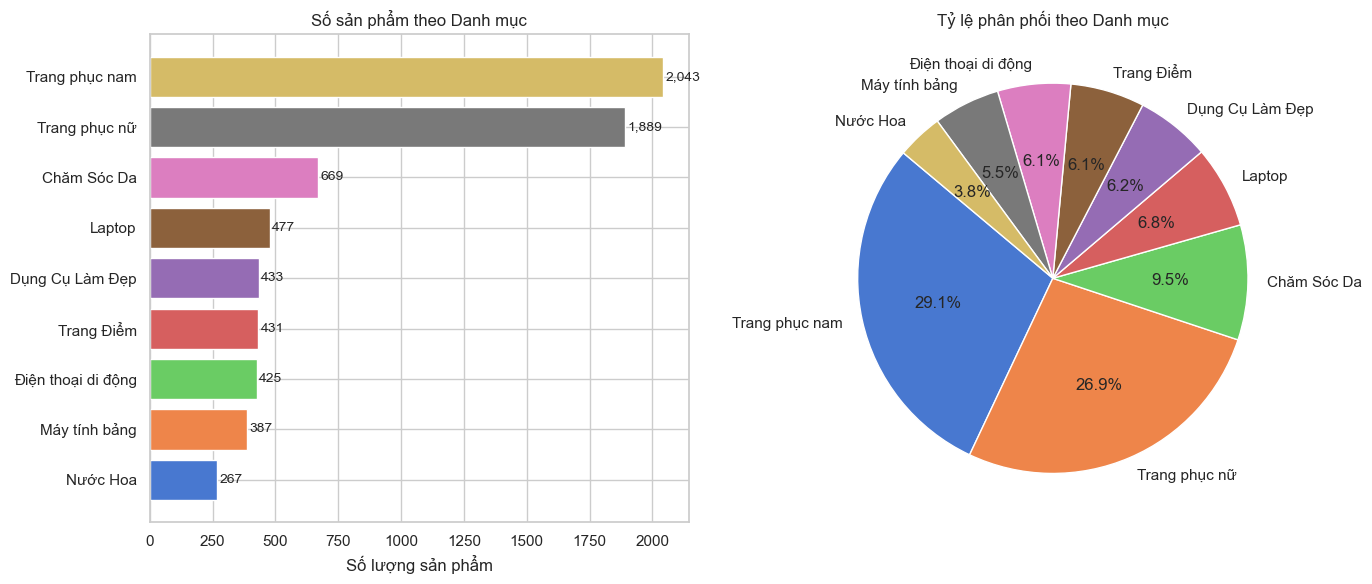

In [12]:
cat_counts = df['Danh mục'].value_counts()
print('=== SỐ LƯỢNG THEO DANH MỤC ===')
print(cat_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Bar chart
axes[0].barh(cat_counts.index[::-1], cat_counts.values[::-1], color=sns.color_palette('muted', len(cat_counts)))
axes[0].set_xlabel('Số lượng sản phẩm')
axes[0].set_title('Số sản phẩm theo Danh mục')
for i, v in enumerate(cat_counts.values[::-1]):
    axes[0].text(v + 10, i, f'{v:,}', va='center', fontsize=10)

# Pie chart
axes[1].pie(cat_counts.values, labels=cat_counts.index, autopct='%1.1f%%',
            colors=sns.color_palette('muted', len(cat_counts)), startangle=140)
axes[1].set_title('Tỷ lệ phân phối theo Danh mục')

plt.tight_layout()
plt.show()

**Nhận xét:**
- **Sự áp đảo của ngành hàng Thời trang:** Nhóm "Trang phục nam" (2,043 sản phẩm, chiếm 29.1%) và "Trang phục nữ" (1,889 sản phẩm, chiếm 26.9%) chiếm ưu thế tuyệt đối, tổng cộng hơn 56% toàn bộ số lượng sản phẩm trong cơ sở dữ liệu. 
- **Phân khúc Sức khỏe - Làm đẹp:** Đứng thứ hai về độ đa dạng. Trong đó, nhu cầu dưỡng da ("Chăm Sóc Da" - 669 sản phẩm) vượt trội rõ rệt so với "Trang Điểm" (431) hay "Nước Hoa" (267).
- **Phân khúc Thiết bị điện tử:** Các mặt hàng như "Laptop", "Điện thoại di động", "Máy tính bảng" chiếm tỷ trọng khiêm tốn hơn (khoảng từ 5.5% - 6.8% cho mỗi nhóm) và khá đồng đều nhau về số lượng phân loại.

> Điều này phản ánh rất đúng bản chất của thị trường thương mại điện tử: Nhóm hàng tiêu dùng nhanh, chạy theo xu hướng, vòng đời ngắn (Quần áo, Mỹ phẩm) luôn đòi hỏi hàng ngàn mẫu mã đa dạng để đáp ứng thị hiếu liên tục thay đổi của người tiêu dùng. Ngược lại, nhóm Điện tử/Công nghệ có vòng đời dài hơn, ít mẫu mã hơn nhưng giá trị cao. Insight này cho thấy nhà bán hàng trong mảng Thời trang hoặc Làm đẹp sẽ phải đối mặt với sự cạnh tranh hiển thị vô cùng khốc liệt giữa một "biển" hàng ngàn đối thủ, đòi hỏi chiến lược marketing và hình ảnh sản phẩm phải rất nổi bật.

## 4.3. Phân tích Giá sản phẩm (nghìn đồng)

In [13]:
gia = df['Giá'].dropna()

print('=== THỐNG KÊ GIÁ (đơn vị: nghìn đồng) ===')
print(gia.describe())

=== THỐNG KÊ GIÁ (đơn vị: nghìn đồng) ===
count      7021.000000
mean        961.001339
std        4428.056102
min           2.500000
25%          95.000000
50%         202.000000
75%         410.000000
max      100000.000000
Name: Giá, dtype: float64


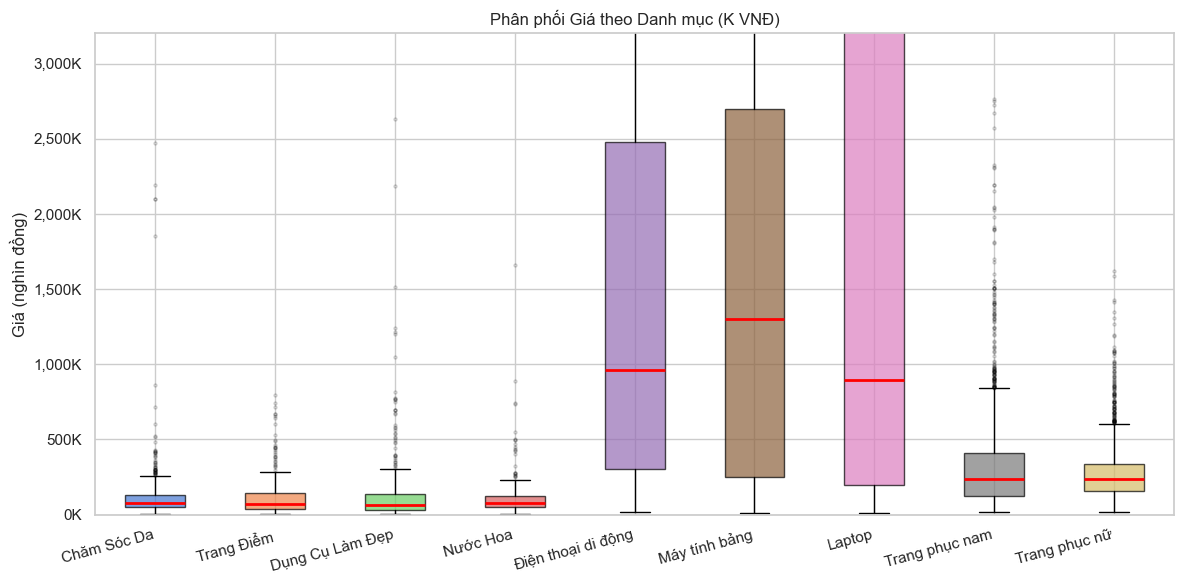

In [14]:
# Giá theo danh mục
fig, ax = plt.subplots(figsize=(12, 6))
cats = df['Danh mục'].unique()
data_by_cat = [df[df['Danh mục'] == c]['Giá'].dropna() for c in cats]
bp = ax.boxplot(data_by_cat, labels=cats, patch_artist=True,
                boxprops=dict(alpha=0.7),
                flierprops=dict(marker='o', markersize=2, alpha=0.2),
                medianprops=dict(color='red', linewidth=2))
colors = sns.color_palette('muted', len(cats))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
ax.set_ylim(0, gia.quantile(0.95))              
ax.set_ylabel('Giá (nghìn đồng)')
ax.set_title('Phân phối Giá theo Danh mục (K VNĐ)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}K'))
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

**Nhận xét:**
- **Sự phân hóa rõ rệt về mặt bằng giá:** Nhóm sản phẩm Thiết bị điện tử (Laptop, Điện thoại di động, Máy tính bảng) có khối hộp (chứa 50% dữ liệu ở giữa) rất dài và nằm ở vị trí cao, mức giá trung vị (đường màu đỏ) quanh mức 900K - 1.3 triệu đồng. Biên độ dao động giá của nhóm này rất rộng.
- **Phân khúc bình dân chiếm trọn nhóm Tiêu dùng nhanh:** Nhóm ngành Thời trang và Sức khỏe - Làm đẹp (Chăm sóc da, Trang điểm, Nước Hoa,...) có thân hộp rất dẹt và bị nén chặt sát đáy (dưới 300K VNĐ). Đây là mức giá "tâm lý" dễ quyết định mua sắm của đại đa số người dùng.
- **Nguồn cung cực dồi dào ở phân khúc cao cấp (Outliers):** Mặc dù trung vị rất thấp, nhưng các ngành như "Chăm sóc da", "Trang phục nam/nữ" lại sở hữu số lượng lớn các điểm ngoại lai (vòng tròn xám) kéo dài lên tận mốc 2 - 3 triệu đồng. Đây đại diện cho các sản phẩm hàng hiệu, mĩ phẩm high-end (cao cấp).

> Insight kinh doanh: Hành vi tiêu dùng trên sàn giao dịch có sự phân rẽ khác biệt. Với nhóm Thời trang & Mỹ phẩm, đây là cuộc chơi của "số lượng và giá rẻ" để kích thích mua sắm bốc đồng (impulse buying) với số lượng đơn hàng khủng. Dù vậy, biểu đồ vẫn cho thấy mặt hàng xa xỉ (luxury) có mức giá hàng triệu đồng vẫn có một thị phần không hề nhỏ (nhiều điểm outlier), mở ra cơ hội sinh lời cao cho các cửa hàng chính hãng (Mall) thay vì chỉ đua nhau giảm giá bán phá đáy.

## 4.4 Phân tích Tỷ lệ Giảm giá

=== THỐNG KÊ GIẢM GIÁ ===
count    7021.000000
mean        0.267143
std         0.223160
min         0.000000
25%         0.020000
50%         0.250000
75%         0.440000
max         0.990000
Name: Giảm giá, dtype: float64


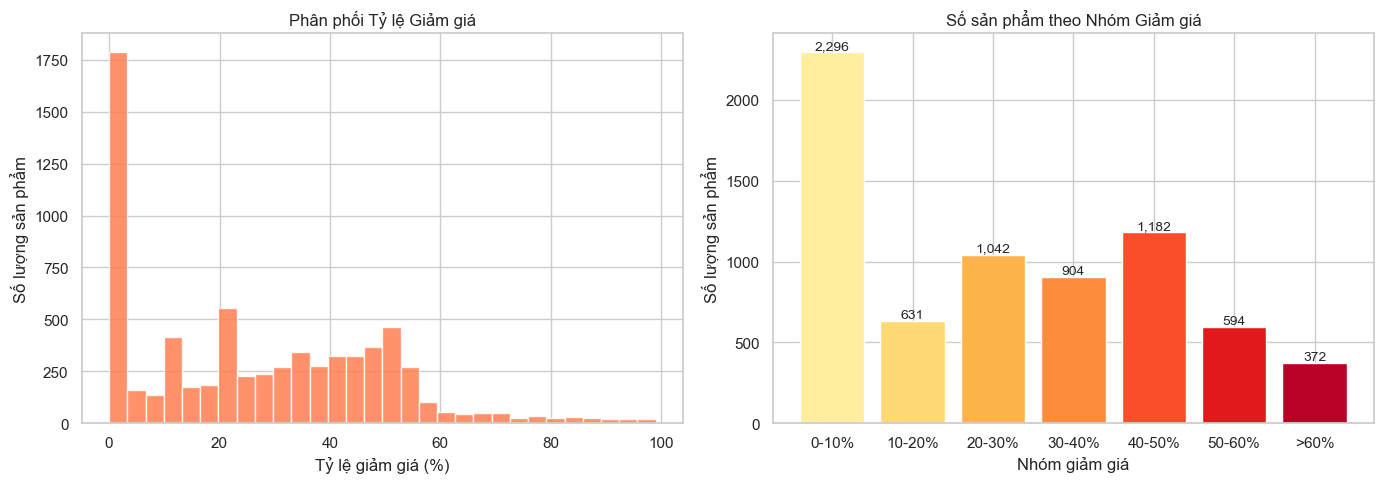

In [15]:
print('=== THỐNG KÊ GIẢM GIÁ ===')
print(df['Giảm giá'].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram giảm giá
axes[0].hist(df['Giảm giá'].dropna() * 100, bins=30, color='coral', edgecolor='white', alpha=0.85)
axes[0].set_xlabel('Tỷ lệ giảm giá (%)')
axes[0].set_ylabel('Số lượng sản phẩm')
axes[0].set_title('Phân phối Tỷ lệ Giảm giá')

# Phân nhóm giảm giá
bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 1.01]
labels = ['0-10%', '10-20%', '20-30%', '30-40%', '40-50%', '50-60%', '>60%']
df['Nhóm giảm giá'] = pd.cut(df['Giảm giá'], bins=bins, labels=labels, include_lowest=True)
group_counts = df['Nhóm giảm giá'].value_counts().sort_index()
axes[1].bar(group_counts.index, group_counts.values, color=sns.color_palette('YlOrRd', len(group_counts)))
axes[1].set_xlabel('Nhóm giảm giá')
axes[1].set_ylabel('Số lượng sản phẩm')
axes[1].set_title('Số sản phẩm theo Nhóm Giảm giá')
for i, v in enumerate(group_counts.values):
    axes[1].text(i, v + 20, f'{v:,}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

**Nhận xét:**
- **Sự phân cực ở nhóm ít/không giảm giá (0-10%):** Nhóm này chiếm số lượng áp đảo tuyệt đối (2,297 sản phẩm). Điều này cho thấy có một lượng rất lớn sản phẩm trên nền tảng bán gần sát với giá gốc ban đầu hoặc chỉ giảm vài phần trăm mang tính chất "tượng trưng".
- **Các mốc "mỏ neo" khuyến mãi (20-50%):** Biểu đồ có sự gia tăng mạnh trở lại và tạo đỉnh ở các nhóm giảm từ 20-30% (1,044 sản phẩm) và đặc biệt là ngưỡng 40-50% (1,182 sản phẩm). Đây là mức giảm lý tưởng nhất trên các sàn TMĐT.
- **Khuyến mãi cực sâu (>50%):** Vẫn có một lượng không nhỏ (khoảng gần 1000 sản phẩm) chấp nhận mức giảm "rất rát" từ 50% đến hơn 60% để thu hút traffic.

> Insight kinh doanh: Có sự tồn tại của hai trường phái định giá song song trên sàn. Một bộ phận lớn người bán chọn chiến lược "everyday low price" (giá rẻ mỗi ngày) – để giá gốc là giá bán cuối cùng (nhóm 0-10%), thường rơi vào ngành hàng điện tử (biên lợi nhuận mỏng) hoặc thương hiệu lớn muốn giữ định vị. Trong khi đó, chiến lược nâng giá niêm yết lên cao rồi "sale nửa giá" (nhóm 40-50%) vẫn là thủ thuật tâm lý cực kỳ phổ biến và hiệu quả, đặc biệt trong ngành hàng Thời trang và Sức khỏe - Làm đẹp, nhằm tạo ra cảm giác "món hời lớn" (bargain) để thúc đẩy khách hàng chốt đơn bốc đồng (impulsive buying).

## 4.5 Phân tích Lượt bán

=== THỐNG KÊ LƯỢT BÁN ===
count      7021.000000
mean        435.705882
std        3752.419530
min           5.000000
25%          12.000000
50%          36.000000
75%         152.000000
max      169100.000000
Name: Đã bán, dtype: float64


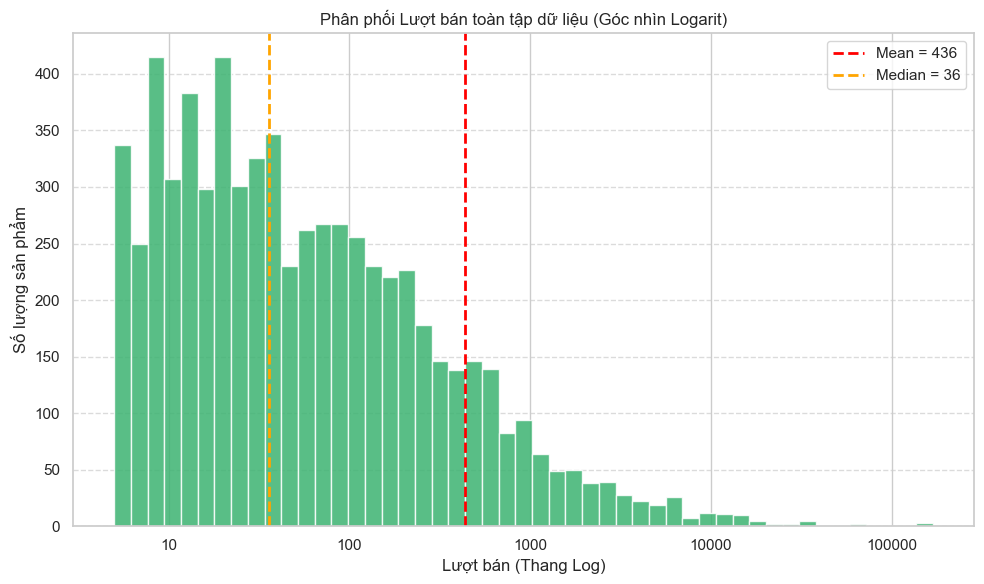

In [16]:
import matplotlib.ticker as ticker
import numpy as np

print('=== THỐNG KÊ LƯỢT BÁN ===')
da_ban = df['Đã bán'].dropna()
print(da_ban.describe())

fig, ax = plt.subplots(figsize=(10, 6))

# Bỏ qua các giá trị 0 vì log(0) không xác định
da_ban_nonzero = da_ban[da_ban > 0]
# Tạo 50 bins theo cấp số nhân (logspace) để các cột rộng đều nhau trên thang log
bins = np.logspace(np.log10(da_ban_nonzero.min()), np.log10(da_ban_nonzero.max()), 50)

# Vẽ Histogram (Trục X thang Log)
ax.hist(da_ban_nonzero, bins=bins, color='mediumseagreen', edgecolor='white', alpha=0.85)

# Đánh dấu Mean và Median để có thêm thông tin phân phối
ax.axvline(da_ban.mean(), color='red', linestyle='--', linewidth=2, label=f"Mean = {da_ban.mean():.0f}")
ax.axvline(da_ban.median(), color='orange', linestyle='--', linewidth=2, label=f"Median = {da_ban.median():.0f}")

ax.set_xscale('log') # Bật chế độ log cho trục X
ax.xaxis.set_major_formatter(ticker.ScalarFormatter()) # Hiển thị số thực thay vì 10^x
ax.set_xlabel('Lượt bán (Thang Log)')
ax.set_ylabel('Số lượng sản phẩm')
ax.set_title('Phân phối Lượt bán toàn tập dữ liệu (Góc nhìn Logarit)')
ax.legend()

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Nhận xét:**
- **Phân phối cực kỳ lệch phải (Right-skewed):** Đa số sản phẩm (~70%) tập trung ở 10-100 lượt bán, nhưng có một số ít sản phẩm bán hàng nghìn lượt.
- **Chênh lệch khủng khiếp Mean vs Median:** Mean = 436 nhưng Median = 36. Chênh lệch 12x cho thấy sự bất bình đẳng cực báo về lượt bán.
- **Hiệu ứng "Winner-takes-most":** Một nhóm nhỏ sản phẩm "siêu bán chạy" kéo trung bình lên cao, trong khi hơn nửa sản phẩm bán dưới 36 lượt.

> **Insight kinh doanh:** Thị trường Lazada tuân theo luật Pareto (80/20): ~20% sản phẩm tạo ~80% doanh số. Hầu hết seller mới sẽ "kẹt" ở vùng 10-100 lượt bán (không gây tổn thất nhưng lợi nhuận thấp). Để thoát khỏi vùng này cần: Tích lũy review nhanh qua khuyến mãi ban đầu, Tối ưu hóa SEO sản phẩm để lên top tìm kiếm.

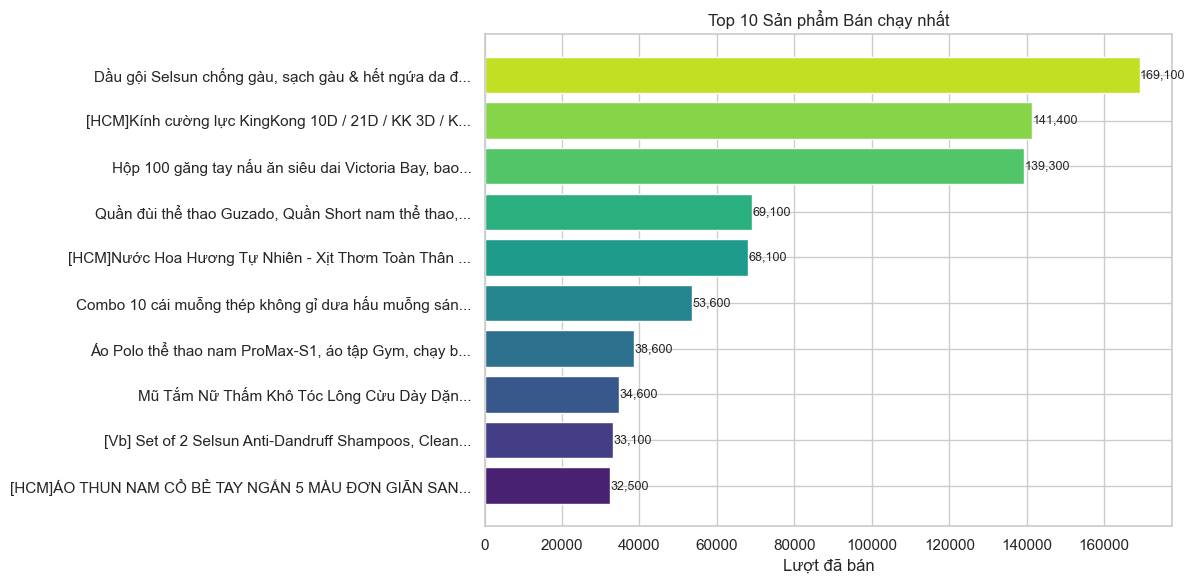

                                           Tên (rút gọn)  Đã bán  Giá (VNĐ)            Danh mục
0  Dầu gội Selsun chống gàu, sạch gàu & hết ngứa da đ...  169100   84,000 đ         Chăm Sóc Da
1  [HCM]Kính cường lực KingKong 10D / 21D / KK 3D / K...  141400   14,850 đ  Điện thoại di động
2  Hộp 100 găng tay nấu ăn siêu dai Victoria Bay, bao...  139300   14,500 đ     Dụng Cụ Làm Đẹp
3  Quần đùi thể thao Guzado, Quần Short nam thể thao,...   69100  105,000 đ      Trang phục nam
4  [HCM]Nước Hoa Hương Tự Nhiên - Xịt Thơm Toàn Thân ...   68100   28,064 đ            Nước Hoa
5  Combo 10 cái muỗng thép không gỉ dưa hấu muỗng sán...   53600    4,100 đ         Chăm Sóc Da
6  Áo Polo thể thao nam ProMax-S1, áo tập Gym, chạy b...   38600  188,100 đ      Trang phục nam
7             Mũ Tắm Nữ Thấm Khô Tóc Lông Cừu Dày Dặn...   34600    4,900 đ          Trang Điểm
8  [Vb] Set of 2 Selsun Anti-Dandruff Shampoos, Clean...   33100  163,000 đ         Chăm Sóc Da
9  [HCM]ÁO THUN NAM CỔ BẺ TAY NGẮN 5 MÀU

In [17]:
# Top 10 sản phẩm bán chạy nhất
top10_sold = df.nlargest(10, 'Đã bán')[['Tên sản phẩm', 'Đã bán', 'Giá', 'Danh mục']].reset_index(drop=True)
top10_sold['Tên (rút gọn)'] = top10_sold['Tên sản phẩm'].str[:50] + '...'
top10_sold['Giá (VNĐ)'] = (top10_sold['Giá'] * 1000).map('{:,.0f}'.format) + ' đ'

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(top10_sold['Tên (rút gọn)'][::-1], top10_sold['Đã bán'][::-1],
               color=sns.color_palette('viridis', 10))
ax.set_xlabel('Lượt đã bán')
ax.set_title('Top 10 Sản phẩm Bán chạy nhất')
for bar, val in zip(bars, top10_sold['Đã bán'][::-1]):
    ax.text(bar.get_width() + 100, bar.get_y() + bar.get_height()/2,
            f'{val:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

print(top10_sold[['Tên (rút gọn)', 'Đã bán', 'Giá (VNĐ)', 'Danh mục']].to_string())

**Nhận xét:**
- **Hiệu ứng "Mega-hit":** Sản phẩm Dầu gội Selsun chống gàu vượt trội tuyệt đối với 169,100 lượt bán, gấp 5 lần sản phẩm cuối top 10 (32,500).
- **Giảm mạnh từ vị trí 2-3:** Kinh cường lực KingKong (141,400) và Găng tay Victoria Bay (139,300) sát nhau, sau đó giảm gấp bậc.
- **Xu hướng giá rẻ:** Khách hàng rất thích săn giá rẻ dẫn đấn top 10 bùng nổ về lượt bán thì xuất những những sản phẩm dưới 30,000.

> **Insight kinh doanh:** Top 10 toàn là sản phẩm FMCG (tiêu dùng nhanh): dầu gội, dụng cụ lao động, quần dùi thể thao — những mặt hàng nhu cầu cao, giá bình dân, dễ tái mua. Dầu gội chống gàu là "hàng chủ lực" chiến lược — bán hàng loạt, xây dựng lòng tin. Seller có thể lợi dụng bán kèm (bundling) các top products này để đẩy doanh số các sản phẩm bán chậm hơn.

## 4.6. Phân tích Điểm & Lượt đánh giá

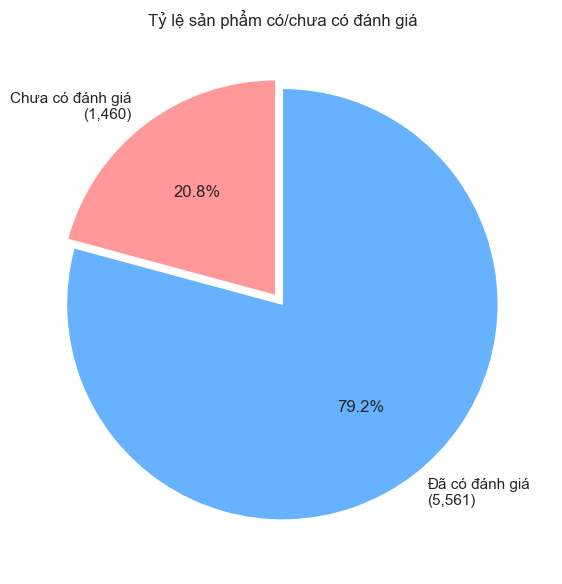

In [18]:
# Tỷ lệ sản phẩm chưa có đánh giá
no_review = df[df['Lượt đánh giá'] == 0].shape[0]
has_review = df[df['Lượt đánh giá'] > 0].shape[0]

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie([no_review, has_review],
       labels=[f'Chưa có đánh giá\n({no_review:,})', f'Đã có đánh giá\n({has_review:,})'],
       autopct='%1.1f%%',
       colors=['#FF9999', '#66B2FF'],
       startangle=90,
       explode=(0.05, 0))
ax.set_title('Tỷ lệ sản phẩm có/chưa có đánh giá')
plt.tight_layout()
plt.show()


**Nhận xét:**

- Tập dữ liệu cho thấy **79.2% sản phẩm** (5,561 sản phẩm) đã có lượt đánh giá từ khách hàng, trong khi **20.8%** (1,460 sản phẩm) chưa có đánh giá. 
- Tỷ lệ sản phẩm đã có đánh giá nhiều hơn sản phẩm không có đánh giá và phản ánh một thị trường có mức độ trao đổi với khách hàng khá tốt.

> **Insight kinh doanh:** Để chuyển đổi nhóm thứ hai này sang nhóm có đánh giá cao (giống như nhóm 79.2%), các seller cần áp dụng **chiến lược marketing** để kích thích lượt mua từ khách hàng, từ đó tích lũy review tích cực. Điều này tạo ra một dây chuyền có lợi: sản phẩm có đánh giá cao → khách tìm kiếm → mua nhiều → feedback tốt. Sản phẩm chưa đánh giá sẽ bị "vô hình hoá" trong thuật toán tìm kiếm nếu không chủ động đẩy mạnh sớm, do đó **chi phí đã bỏ cho quản trị kho hàng sẽ bị lãng phí** nếu để sản phẩm không có đánh giá quá lâu.

## 4.7. Phân tích theo Địa điểm

=== TOP 15 ĐỊA ĐIỂM ===
Địa điểm
Hồ Chí Minh              2349
China                    1459
Hà Nội                   1010
Hong Kong                 756
Nước ngoài                377
Nam Định                  163
Bình Dương                145
Hưng Yên                   75
Thành phố Hồ Chí Minh      70
Hải Phòng                  48
Tây Ninh                   46
Đà Nẵng                    45
Tiền Giang                 44
Long An                    36
Bạc Liêu                   33
Name: count, dtype: int64


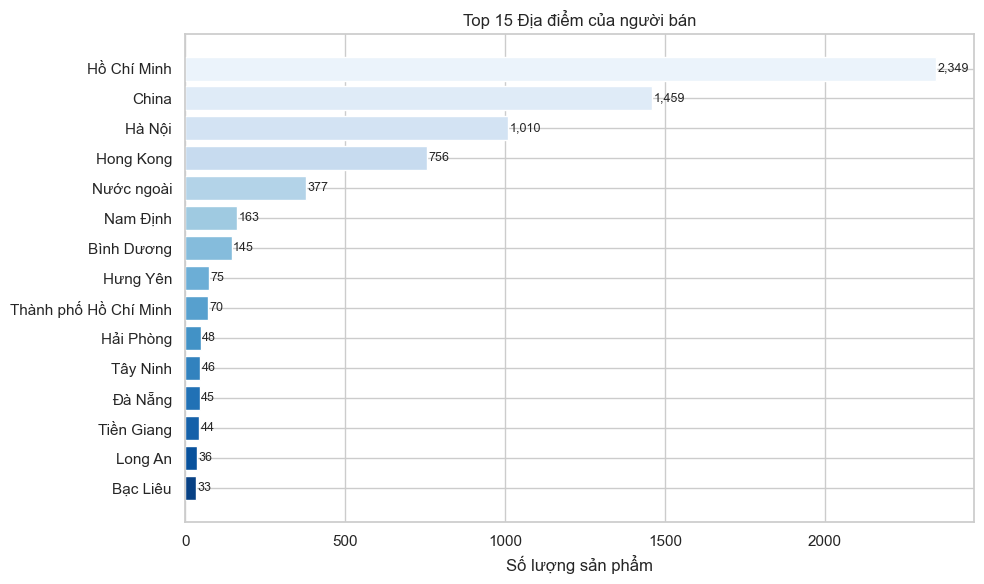

In [19]:
loc_counts = df['Địa điểm'].value_counts().head(15)
print('=== TOP 15 ĐỊA ĐIỂM ===')
print(loc_counts)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(loc_counts.index[::-1], loc_counts.values[::-1],
        color=sns.color_palette('Blues_r', len(loc_counts)))
ax.set_xlabel('Số lượng sản phẩm')
ax.set_title('Top 15 Địa điểm của người bán')
for i, v in enumerate(loc_counts.values[::-1]):
    ax.text(v + 5, i, f'{v:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

**Nhận xét:**
- **Sự áp đảo của TP. Hồ Chí Minh:** Chiếm 33.4% (2,349 sản phẩm), vượt trội tuyệt đối so với các địa điểm khác.
- **Hai địa điểm nổi bật tiếp theo:** China (1,459) và Hà Nội (1,010) chiếm ~36% tổng cộng.
- **Tập trung cao:** Top 3 địa điểm chiếm ~68% toàn bộ sản phẩm.

> **Insight kinh doanh:** TP.HCM là hub logistics chính của Lazada Việt Nam, tập trung kho hàng và cửa hàng lớn. Nhập khẩu trực tiếp từ Trung Quốc/Hong Kong chiếm tỷ trọng đáng kể, cho thấy chiến lược nhập khẩu trực tiếp của các seller. Các tỉnh lẻ chưa được phát triển đầy đủ — cơ hội lớn cho seller ngoại tỉnh xâm nhập thị trường hoặc tái cân bằng logistics.

## 4.8. Tương quan giữa các biến số

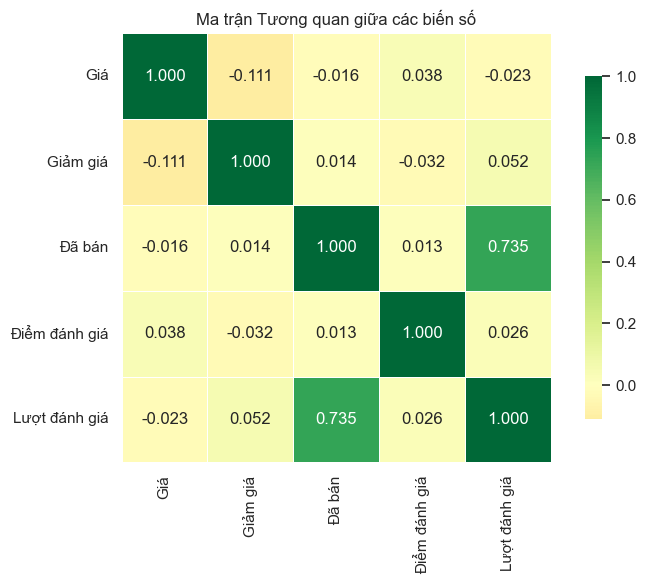

In [20]:
num_cols = ['Giá', 'Giảm giá', 'Đã bán', 'Điểm đánh giá', 'Lượt đánh giá']
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='RdYlGn',
            center=0, square=True, linewidths=0.5,
            ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Ma trận Tương quan giữa các biến số')
plt.tight_layout()
plt.show()

**Nhận xét:**
- **Hầu hết các biến số có tương quan yếu hoặc gần như không có tương quan** (hầu hết giá trị từ -0.111 đến 0.052).
- **Chỉ có một mối tương quan mạnh:** Đã bán ↔ Lượt đánh giá (0.735) — sản phẩm bán nhiều tích lũy đánh giá nhiều.
- **Giá không ảnh hưởng nhiều:** Mức giá gần như độc lập với % giảm giá, lượt bán, hay đánh giá (tương quan gần 0).

> **Insight kinh doanh:** Thành công trên Lazada không phải do giá cao hay giảm giá mạnh, mà phụ thuộc vào **dây chuyền: bán nhiều → nhận nhiều review → thuật toán ưu tiên → bán tiếp tục nhiều**. Seller mới cần đẩy lượng ban đầu để tích lũy review, chứ không phải chỉ cạnh tranh giá.